In [1]:
import pandas as pd
b = pd.read_csv("../outputs/benchmark_mlbtr_vs_model.csv")
print(b.columns.tolist())
print(b.head(3).to_string())

['player_name', 'signing_year', 'mlbtr_rank', 'mlbtr_pos', 'mlbtr_years', 'mlbtr_total_m', 'mlbtr_aav_m', 'key', 'actual_aav_m', 'actual_years', 'actual_total', 'model_aav_m', 'actual_total_m', 'mlbtr_err', 'model_err']
      player_name  signing_year  mlbtr_rank mlbtr_pos  mlbtr_years  mlbtr_total_m  mlbtr_aav_m             key  actual_aav_m  actual_years  actual_total  model_aav_m  actual_total_m  mlbtr_err  model_err
0  Cody Bellinger          2024           2       NaN           12          264.0        22.00  cody bellinger     26.666667           3.0    80000000.0    15.401630            80.0  -4.666667 -11.265036
1     Blake Snell          2024           4       NaN            7          200.0        28.57     blake snell     31.000000           2.0    62000000.0    26.777230            62.0  -2.430000  -4.222770
2      Aaron Nola          2024           5       NaN            6          150.0        25.00      aaron nola     24.571429           7.0   172000000.0    24.779017   

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../outputs/figures", exist_ok=True)
BLUE, ORANGE, GRAY = "#0072B2", "#E69F00", "#888888"   # colorblind-safe
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})

b = pd.read_csv("../outputs/benchmark_mlbtr_vs_model.csv")
b = b.dropna(subset=["actual_aav_m", "model_aav_m", "mlbtr_aav_m"]).copy()
print(len(b), "players")

120 players


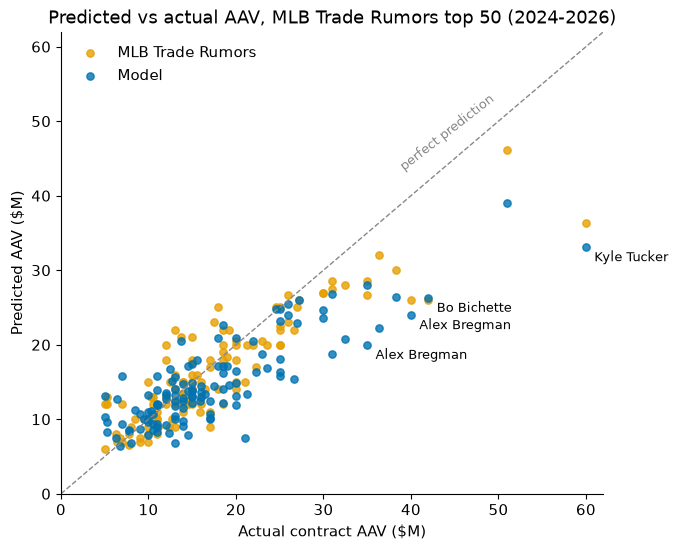

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(b["actual_aav_m"], b["mlbtr_aav_m"], s=28, color=ORANGE, alpha=0.8, label="MLB Trade Rumors")
ax.scatter(b["actual_aav_m"], b["model_aav_m"], s=28, color=BLUE, alpha=0.8, label="Model")
lim = max(b["actual_aav_m"].max(), b["model_aav_m"].max(), b["mlbtr_aav_m"].max()) + 2
ax.plot([0, lim], [0, lim], color=GRAY, linestyle="--", linewidth=1)
ax.text(lim * 0.62, lim * 0.70, "perfect prediction", color=GRAY, rotation=38, fontsize=9)

for _, r in b.reindex(b["model_err"].abs().sort_values(ascending=False).index).head(4).iterrows():
    ax.annotate(r["player_name"], (r["actual_aav_m"], r["model_aav_m"]),
                textcoords="offset points", xytext=(6, -10), fontsize=9)

ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Actual contract AAV ($M)")
ax.set_ylabel("Predicted AAV ($M)")
ax.set_title("Predicted vs actual AAV, MLB Trade Rumors top 50 (2024-2026)")
ax.legend(frameon=False, loc="upper left")
fig.savefig("../outputs/figures/predicted_vs_actual.png", dpi=200, bbox_inches="tight")
plt.show()

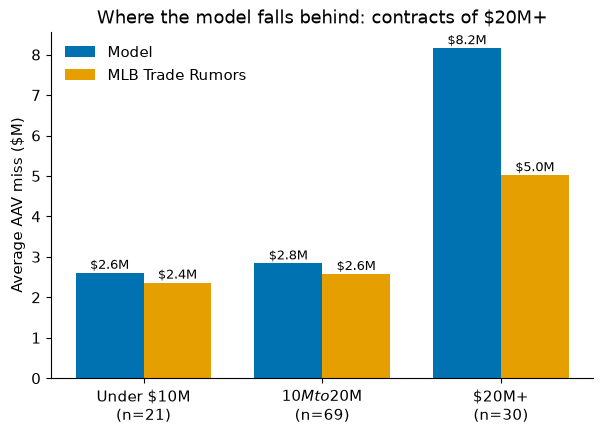

In [4]:
bands = pd.cut(b["actual_aav_m"], [0, 10, 20, 200], labels=["Under $10M", "$10M to $20M", "$20M+"])
g = pd.DataFrame({"band": bands,
                  "Model": b["model_err"].abs(),
                  "MLB Trade Rumors": b["mlbtr_err"].abs()}).groupby("band", observed=True)
mae = g.mean()
n = g.size()

fig, ax = plt.subplots(figsize=(7, 4.5))
x = range(len(mae)); w = 0.38
bars1 = ax.bar([i - w/2 for i in x], mae["Model"], w, color=BLUE, label="Model")
bars2 = ax.bar([i + w/2 for i in x], mae["MLB Trade Rumors"], w, color=ORANGE, label="MLB Trade Rumors")
for bars in (bars1, bars2):
    for rect in bars:
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.1,
                f"${rect.get_height():.1f}M", ha="center", fontsize=9)
ax.set_xticks(list(x))
ax.set_xticklabels([f"{k}\n(n={n[k]})" for k in mae.index])
ax.set_ylabel("Average AAV miss ($M)")
ax.set_title("Where the model falls behind: contracts of $20M+")
ax.legend(frameon=False)
fig.savefig("../outputs/figures/error_by_size.png", dpi=200, bbox_inches="tight")
plt.show()

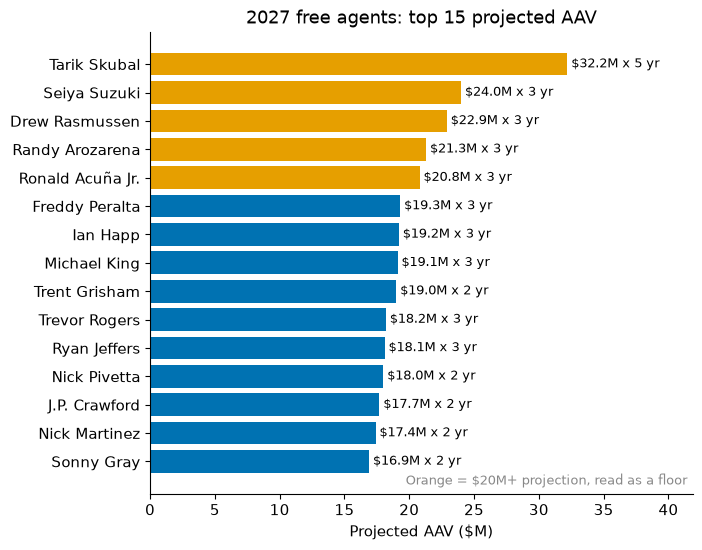

In [5]:
p = pd.read_csv("../outputs/fa_2027_contract_projections.csv")
top = p.sort_values("pred_aav_m", ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 6))
colors = [ORANGE if f else BLUE for f in top["lower_bound"]]
ax.barh(top["player_name"], top["pred_aav_m"], color=colors)
for y, (v, yrs) in enumerate(zip(top["pred_aav_m"], top["pred_years"])):
    ax.text(v + 0.3, y, f"${v:.1f}M x {int(yrs)} yr", va="center", fontsize=9)
ax.set_xlim(0, top["pred_aav_m"].max() * 1.3)
ax.set_xlabel("Projected AAV ($M)")
ax.set_title("2027 free agents: top 15 projected AAV")
ax.text(0.99, 0.02, "Orange = $20M+ projection, read as a floor",
        transform=ax.transAxes, ha="right", fontsize=9, color=GRAY)
fig.savefig("../outputs/figures/top_2027_projections.png", dpi=200, bbox_inches="tight")
plt.show()